In [1]:
# !pip install pettingzoo

In [2]:
import functools
import random
from copy import copy

import numpy as np
from gymnasium.spaces import Discrete, MultiDiscrete
from collections import defaultdict
import time
import os
import matplotlib.pyplot as plt

from pettingzoo import ParallelEnv
import seaborn as sns
import pandas as pd
import concurrent.futures
import time
from matplotlib.ticker import MaxNLocator # 1. Importa questo

In [3]:
class Config:
    def __init__(self, num_agents, env_num):
        self.num_agents = num_agents
        self.env_num = env_num

        # ENV 1: Cross Shape (21 States) - 5x5 Grid (Padded to 7x7 for safety if you want)
        # 0 = Wall, 1-21 = Unique State IDs
        self.grid_1 = np.array([
            [1,  2,  0,  3,  4],
            [5,  6,  0,  7,  8],
            [9, 10, 11, 12, 13],  # 11 is the Doorway (Center)
            [14,15,  0, 16, 17],
            [18,19,  0, 20, 21]
        ])

        # ENV 2: Four Rooms (36 States) - 7x7 Grid
        self.grid_2 = np.array([
            [0,  1,  2,  0,  3,  4,  0],
            [5,  6,  7,  0,  8,  9, 10],
            [11,12, 13, 14, 15, 16, 17], # Horizontal Hallway
            [0,  0, 18,  0, 19,  0,  0], # Vertical connectors
            [20,21, 22, 23, 24, 25, 26], # Horizontal Hallway
            [27,28, 29,  0, 30, 31, 32],
            [0, 33, 34,  0, 35, 36,  0]
        ])

    def get_grid(self):
        # FIX: Return grid_1 for Env 1, grid_2 for Env 2
        if self.env_num == 1:
            return self.grid_1
        else:
            return self.grid_2

    def set_initial_position(self):
        """
        Defines Start/Goal coordinates (y, x) for each scenario.
        These match the figures in the PDF.
        """
        positioning = {}

        # --- ENVIRONMENT 1 (2 Robots, 1 Door) ---
        if self.env_num == 1:
            # Robot 1: Top-Left (State 1) -> Bottom-Right (State 21)
            positioning["player_0"] = [(0, 0), (4, 4)]

            # Robot 2: Top-Right (State 4) -> Bottom-Left (State 18)
            positioning["player_1"] = [(0, 4), (4, 0)]

            # Doorway: Center (State 11)
            positioning["collision"] = [(2, 2)]

        # --- ENVIRONMENT 2 (2 or 4 Robots, 4 Doors) ---
        else:
            # [cite_start]Figure 3[cite: 71, 90]: Robots move to opposite corners

            # P0: Top-Left Room (State 6) -> Bottom-Right Room (State 31)
            positioning["player_0"] = [(1, 1), (5, 5)]

            # P1: Top-Right Room (State 9) -> Bottom-Left Room (State 28)
            positioning["player_1"] = [(1, 5), (5, 1)]

            # P2: Bottom-Left Room (State 28) -> Top-Right Room (State 9)
            positioning["player_2"] = [(5, 1), (1, 5)]

            # P3: Bottom-Right Room (State 31) -> Top-Left Room (State 6)
            positioning["player_3"] = [(5, 5), (1, 1)]

            # [cite_start]4 Doorways [cite: 102]
            # These are the "Choke Points" connecting Rooms to Hallways
            positioning["collision"] = [
                (2, 1), # Exit from Top-Left Room (State 12)
                (2, 5), # Exit from Top-Right Room (State 16)
                (4, 1), # Exit from Bot-Left Room (State 21)
                (4, 5)  # Exit from Bot-Right Room (State 25)
            ]

        return positioning

    def get_grid_config_init(self):
        return self.get_grid(), self.set_initial_position()

In [4]:
# what we need to do in this class is trying to store information about all of steps

class Player:
  def __init__(self, name, start_pos, goal_pos):
      self.name = name
      self.start_pos = start_pos
      self.goal_pos = goal_pos
      self.check_goal = False

      self.step_to_reach_goal = 0

      # Unpack tuples: start_pos is usually (Row, Col)
      # We map Row -> y (Vertical), Col -> x (Horizontal)
      self.y, self.x = start_pos


      # Save goal for termination checks in the Env
      self.goal_pos = goal_pos


      self.sequence = []
      self.sequence.append((self.y, self.x))

  def reset(self):
     self.check_goal = False
     self.step_to_reach_goal = 0

  def update_step(self, step):
    self.step_to_reach_goal = step

  def get_step(self):
    return self.step_to_reach_goal


  def get_sequence_steps(self):
    return self.sequence

  def get_state(self, grid_map):
      """
      Returns the State ID (Integer) from the grid at current position.
      Used for Q-Table lookups.
      """
      # CRITICAL FIX: Access as [Row, Col] -> [y, x]
      return grid_map[self.y, self.x]

  def get_position(self):
      """Returns (Row, Col) for the Environment to use."""
      return (self.y, self.x)

  def set_position(self, r, c):
        # Niente scambio! r va in y, c va in x
        self.y = r 
        self.x = c
        self.sequence = [(r, c)]


  def step(self, action, grid_map):
        """
        Executes the move with 80% success / 20% slip probability.
        action: 0=N, 1=S, 2=E, 3=W, 4=Coordinate
        grid_map: 0=Wall, 1=Floor
        """

        # --- PART 1: STOCHASTIC PHYSICS (The 80/20 Rule) ---
        # Map intended action to [Slip Left, Slip Right]
        # 0=N, 1=S, 2=E, 3=W
        slips = {
            0: [3, 2], # North (0) -> Slips West (3) or East (2)
            1: [2, 3], # South (1) -> Slips East (2) or West (3)
            2: [0, 1], # East  (2) -> Slips North (0) or South (1)
            3: [1, 0]  # West  (3) -> Slips South (1) or North (0)
        }

        # CLEANER APPROACH
        outcomes = [action, slips[action][0], slips[action][1]]
        probs = [0.8, 0.1, 0.1]

        # 1 line of code. No math errors possible.
        actual_move = np.random.choice(outcomes, p=probs)


        # --- PART 2: CALCULATE COORDINATES ---
        # Remember: Matrix (0,0) is Top-Left.
        # North decreases Y (Row). South increases Y.
        next_y, next_x = self.y, self.x

        if actual_move == 0:   # North
            next_y -= 1        # Move UP (lower index)
        elif actual_move == 1: # South
            next_y += 1        # Move DOWN (higher index)
        elif actual_move == 2: # East
            next_x += 1
        elif actual_move == 3: # West
            next_x -= 1

        # --- PART 3: WALL & BOUNDARY CHECK ---
        rows, cols = grid_map.shape

        # Check A: Out of Bounds?
        if not (0 <= next_y < rows and 0 <= next_x < cols):
            # Hit edge of map: Stay put
            next_y, next_x = self.y, self.x

        # Check B: Wall? (Assuming 0 is Wall)
        elif grid_map[next_y, next_x] == 0:
            # Hit wall: Stay put
            next_y, next_x = self.y, self.x


        # --- PART 4: UPDATE STATE ---
        self.y = next_y
        self.x = next_x
        self.sequence.append((self.y, self.x))


In [5]:
class Environment(ParallelEnv):
    metadata = {"name": "Environment"}

    def __init__(self, num_agents, env_num):
        self.env_num = env_num
        self.steps = 0

        # we need to define the question of FOV {ACTIVE_PERCEPTRON}

        # 1. Load Config
        self.conf = Config(num_agents, env_num)
        self.grid, self.initial_position = self.conf.get_grid_config_init()
        self.doorway_coords = self.initial_position.get("collision", []) # in this line we are recovering all of postion of the doorways inside the grid


        # 2. Setup Agent Names
        if num_agents == 4:
            self.agents = ["player_0", "player_1", "player_2", "player_3"]
        else:
            self.agents = ["player_0", "player_1"]

        self.terminations = {a: False for a in self.agents} # what we want to understand if in a episode some agent ending up to goal
        self.infos = {a: {} for a in self.agents}
        self.observations = {a : {} for a in self.agents} # observation is gave for the updated q-table
        self.collision = 0


        # 3. FIX: Use a Dictionary, not a List
        self.agents_obj = {}

        for name in self.agents:
            # FIX: Use self.initial_position (from Config), not 'positioning'
            if name in self.initial_position:
                data = self.initial_position[name]
                print(data)
                start_pos = data[0]
                goal_pos  = data[1]

                # Create Player
                self.agents_obj[name] = Player(name, start_pos, goal_pos)



    def reset(self, seed=None, options=None):
        self.steps = 0
        self.collision = 0
        self.finish_times = {a: 0 for a in self.agents}
        # Reset termination logic
        self.terminations = {a: False for a in self.agents}
        observations = {}
        infos = {a: {} for a in self.agents}

        for name, player in self.agents_obj.items():
            # 1. Reset Physics
            # Assuming player.start_pos is stored as (y, x)
            #print(player.start_pos[0])
            player.reset() 
            player.set_position(player.start_pos[0], player.start_pos[1])

            # 2. Generate Correct Observation (Dict)
            # This MUST match the structure in 'step' so the Agent can read it.
            observations[name] = {
                "id": player.get_state(self.grid),
                "coords": player.get_position()
            }

            infos[name] = {
                "step": player.get_step() 
            }

        # CRITICAL FIX: Return exactly 2 values
        return observations, self.terminations,infos

    def step(self, actions):
        self.steps += 1
        self.collision = 0
        rewards = {a: 0.0 for a in self.agents}
        # Default: Not terminated
        infos = {a: {} for a in self.agents}
        observations = {}

        for name, action in actions.items():
            player = self.agents_obj[name]
            if player.check_goal:
                continue
            player.step(action, self.grid)

        # --- 2. OBSERVATIONS (For EVERYONE) ---
        # Even finished agents need to report their position (so others can see them)
        current_positions = {}
        for name in self.agents:
            player = self.agents_obj[name]
            pos = player.get_position()
            current_positions[name] = pos

            # Send Observation
            observations[name] = {
                "id": player.get_state(self.grid),
                "coords": pos
            }

            #print(observations)

        agents_at_pos = defaultdict(list)
        for name in self.agents:
            # We use current_positions which you calculated earlier in step()
            pos = current_positions[name]
            agents_at_pos[pos].append(name)

        # 2. Check Doorways Only
        for door_pos in self.doorway_coords:
            agents_here = agents_at_pos[door_pos]
            
            # If 2 or more robots are in this door
            if len(agents_here) > 1:
                self.collision += 1  # Count 1 Accident
                
                # Punish EVERYONE involved
                for name in agents_here:
                    rewards[name] -= 35

        # --- TERMINATION / GOAL LOGIC ---
        for name in self.agents:
            player = self.agents_obj[name]
            #print(infos)
            #print(name)
            
            # Skip if already done
            if player.check_goal:
                self.terminations[name] = True 
                continue

            # Check Goal
            if player.get_position() == player.goal_pos:
                #print(f"{name} reached goal!")
                player.check_goal = True
                player.update_step(self.steps)
                
                self.terminations[name] = True
                rewards[name] += 10 # One-time Reward
            
            else:
                self.terminations[name] = False


        for name in self.agents:
            player = self.agents_obj[name]
            infos[name] = {
                "step": player.get_step() 
            }
        

       # print(f"DEBUG STEP {self.steps}: Terms={self.terminations}: step{self.infos}")
        return observations, rewards, self.terminations, self.collision, infos


    # API Requirement
    def action_space(self, agent): return self.action_spaces[agent]
    def observation_space(self, agent): return self.observation_spaces[agent]


In [6]:
class IndependentQLearner:
    def __init__(self, action_size, num_states, alpha=0.1, gamma=0.98,
                 epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.999):

        # 1. Dimensions
        self.action_size = action_size
        self.num_states = num_states

        # 2. Hyperparameters
        self.alpha = alpha      # Learning Rate
        self.gamma = gamma      # Discount Factor
        self.epsilon = epsilon  # Exploration Rate
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

        # 3. Q-Table (State-Aware)
        # Instead of np.zeros(action_size), we need a table for every cell.
        # Dimensions: [States, Actions]
        self.q_table = np.zeros((num_states + 1 , action_size))

    def select_greedy(self, state):
        """
        Helper to pick the best action for a specific state, handling ties randomly.
        """
        # Get Q-values for this specific cell
        q_values = self.q_table[state]

        # Find the max value
        max_val = np.max(q_values)

        # Find all actions that have this max value (tie-breaking)
        optimal_actions = np.flatnonzero(np.isclose(q_values, max_val))

        return np.random.choice(optimal_actions)

    def select_action(self, state):
        """
        Epsilon-Greedy Selection.
        Requires 'state' input because the decision depends on where the agent is.
        """
        # Exploration
        if np.random.random() < self.epsilon:
            return np.random.randint(self.action_size)

        # Exploitation
        else:
            return self.select_greedy(state)

    def update(self, state, action, reward, next_state):
        """
        Standard Q-Learning Update.
        Requires current state AND next state.
        """

        # 1. Get Old Value (Q(s,a))
        # CORRECT: Access the specific cell for the action taken
        old_val = self.q_table[state, action]

        # 2. Get Max Future Value (max Q(s', a'))
        # This is correct (max over the row of the next state)
        max_future = np.max(self.q_table[next_state])

        # 3. Update Rule
        # Q(s,a) <- Q(s,a) + alpha * [Reward + gamma * max(Q(s')) - Q(s,a)]
        new_val = old_val + self.alpha * (reward + self.gamma * max_future - old_val)

        self.q_table[state, action] = new_val

    def update_epsilon(self):
        """
        Decays the exploration rate.
        Usually called at the end of an episode, not every step.
        """
        self.epsilon *= self.epsilon_decay
        self.epsilon = max(self.epsilon_min, self.epsilon)

In [7]:

class SparseQLearner:
    def __init__(self, agent_id, num_states, action_size=5,
                 alpha=0.1, gamma=0.98, epsilon=1.0,
                 epsilon_min=0.01, epsilon_decay=0.999):

        self.agent_id = agent_id
        self.action_size = action_size

        # Hyperparameters
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay

        # --- TABLE 1: LOCAL Q-TABLE (Matrix) ---
        # Used for Meta-Decision and Navigation
        # Dimensions: [State_ID, Action]
        self.q_local = np.zeros((num_states + 1, action_size))

        # --- TABLE 2: COMMON Q-TABLE (Dictionary) ---
        # Used for Collision Avoidance
        # Key: (Global_State_Tuple, Physical_Action)
        self.q_common = defaultdict(float) 

    # ======================================================
    # DECISION METHODS (READ)
    # ======================================================

    def get_meta_action(self, state_id):
        """
        Step 1: Choose intent using Epsilon-Greedy on Local Table.
        Returns 0-4.
        """
        return self._get_greedy(self.q_local[state_id])

    def get_physical_action_local(self, state_id):
        """
        Step 2A: Fallback. Choose physical move (0-3) using Local Table.
        """
        # Slice [0:4] to ignore 'Coordinate' action for physical movement
        q_vals = self.q_local[state_id][:4]
        return self._get_greedy(q_vals)

    def get_physical_action_common(self, global_state):
        """
        Step 2B: Active. Choose physical move (0-3) using Common Table.
        """
        q_vals = [self.q_common[(global_state, a)] for a in range(4)]
        return self._get_greedy(q_vals)

    # ======================================================
    # LEARNING METHODS (WRITE)
    # ======================================================

    def update_local(self, state_id, action, reward, next_state_id):
        """
        Updates Q* (Local Matrix). Call this EVERY step.
        """
        old_val = self.q_local[state_id, action]
        max_next = np.max(self.q_local[next_state_id])

        # Standard Update
        self.q_local[state_id, action] += self.alpha * (reward + self.gamma * max_next - old_val)

    def update_common(self, global_state, physical_action, reward, next_global_state):
        """
        Updates Q^C (Common Dict). Call this ONLY if Active + Coordinated.
        """
        key = (global_state, physical_action)
        old_val = self.q_common[key]

        # Bootstrap from next state in Common Table
        next_vals = [self.q_common[(next_global_state, a)] for a in range(4)]
        max_next = max(next_vals) if next_vals else 0.0

        # Standard Update
        self.q_common[key] += self.alpha * (reward + self.gamma * max_next - old_val)

    # ======================================================
    # HELPERS
    # ======================================================
    def update_epsilon(self):
        self.epsilon *= self.epsilon_decay
        self.epsilon = max(self.epsilon_min, self.epsilon)

    def _get_greedy(self, q_vals):
        """Helper to pick max value with random tie-breaking"""
        # Ensure q_vals is a numpy array for easy math
        vals = np.array(q_vals)
        max_val = np.max(vals)
        best_indices = np.flatnonzero(np.isclose(vals, max_val))
        return np.random.choice(best_indices)

In [8]:
class Training:
    def __init__(self, num_agents, env_num):
        self.env = Environment(num_agents, env_num)
        self.env_num = env_num
        self.num_agents = num_agents
        self.NUM_EPISODES = 10000
        self.MAX_STEPS = 100

        if self.env_num == 1:
          self.num_states = 21 
        else:
          self.num_states = 36 

        # first grid 21
        # second grid 36

    def replay_all_agents(self, delay=0.3):
        """
        Plays back the sequence for ALL agents simultaneously.
        Handles different path lengths and visualizes collisions.
        """
        print("Preparing Replay for all agents...")
        time.sleep(1)

        # 1. Collect paths for all agents
        # We need to know the max steps to run the loop long enough
        paths = {}
        max_steps = 0

        for name, player in self.env.agents_obj.items():
            paths[name] = player.sequence # List of (y, x)
            if len(player.sequence) > max_steps:
                max_steps = len(player.sequence)

        rows, cols = self.env.grid.shape

        # 2. Iterate through time (Frame by Frame)
        for t in range(max_steps):

            # A. Clear Screen
            os.system('cls' if os.name == 'nt' else 'clear')
            print(f"Step: {t}/{max_steps}")

            # B. Determine Current Positions for this Frame
            current_positions = {}
            for name in self.env.agents:
                path = paths[name]

                # If agent is still moving, get position at t
                if t < len(path):
                    current_positions[name] = path[t]
                # If agent finished early, keep them at their last position (Parking Brake)
                else:
                    current_positions[name] = path[-1]

            # C. Draw the Grid
            print("+" + "-" * (cols * 2) + "+") # Top Border

            for r in range(rows):
                row_str = "|"
                for c in range(cols):

                    # --- CELL DRAWING LOGIC ---

                    # 1. Check for Agents at this specific cell (r, c)
                    agents_here = []
                    for name, pos in current_positions.items():
                        if pos == (r, c):
                            # Get a short ID (e.g., "player_0" -> "0")
                            short_id = name.split('_')[-1]
                            agents_here.append(short_id)

                    # 2. Determine what to print
                    if len(agents_here) > 1:
                        row_str += "X " # Collision! (Multiple agents)
                    elif len(agents_here) == 1:
                        row_str += f"{agents_here[0]} " # Single Agent ID
                    elif self.env.grid[r, c] == 0:
                        row_str += "█ " # Wall
                    # Check if this cell is ANY agent's goal
                    elif any(self.env.agents_obj[n].goal_pos == (r,c) for n in self.env.agents):
                        row_str += "G " # Goal
                    elif (r, c) in self.env.doorway_coords:
                        row_str += "D " # Doorway
                    else:
                        row_str += ". " # Empty Floor

                row_str += "|"
                print(row_str)

            print("+" + "-" * (cols * 2) + "+") # Bottom Border

            # D. Wait
            time.sleep(delay)

        print("Replay Finished.")

    def evaluate(self, agents, num_eval_episodes=32):
        """
        Runs greedy episodes (epsilon=0) to test true performance.
        Returns: Average reward per agent.
        """
        # 1. Save old epsilons and force Greedy (Epsilon = 0)
        saved_eps = {}
        for name, agent in agents.items():
            saved_eps[name] = agent.epsilon
            agent.epsilon = 0.0 # Turn off exploration [cite: 119]

        total_eval_reward = 0

        for _ in range(num_eval_episodes):
            obs, terms, _ = self.env.reset()

            for step in range(self.MAX_STEPS):
                actions = {}
                for name in agents:
                    # Only ask if not done
                    if not terms[name]:
                        state_id = obs[name]["id"]
                        # Select Action (Will be Greedy since epsilon=0)
                        actions[name] = agents[name].select_action(state_id)

                next_obs, rewards, terms, truncs, infos = self.env.step(actions)

                #print(infos)

                # Accumulate Reward (No Update!)
                for name in agents:
                    total_eval_reward += rewards[name]
                
                if all(terms.values()):
                    break
            

                obs = next_obs



        # 2. Restore Epsilons (Resume Training Mode)
        for name, agent in agents.items():
            agent.epsilon = saved_eps[name]


        # 3. Calculate Average
        # [cite_start]Average over 32 episodes AND over agents [cite: 120]
        avg_reward = total_eval_reward / (num_eval_episodes * self.num_agents)
        return avg_reward

    def sparse(self): # maybe also 4 agent 
         # 1. Initialize Agents
        decay_rate = (0.05 / 1.0) ** (1 / 6666) 
        agents = {
            "player_0": IndependentQLearner(
                action_size=4,
                num_states=self.num_states,
                alpha=0.05,          # Conservative learning rate for stochastic env
                gamma=0.98,         # Required by homework
                epsilon=1.0,        # Required by homework
                epsilon_min=0.05,   # Stop decaying here
                epsilon_decay=decay_rate # Calculated to hit 2/3rds mark
            ),
            "player_1": IndependentQLearner(
                action_size=4,
                num_states=self.num_states,
                alpha=0.05,
                gamma=0.98,
                epsilon=1.0,
                epsilon_min=0.05,
                epsilon_decay=decay_rate
            ),
        }

        # [CHANGE 1] Structure History to hold individual lists
        history = {
            "train_rewards": [], # Noisy training data
            "eval_rewards": [],  # Clean evaluation data
            "eval_points": [],   # X-axis points (0, 1000...)
            "collisions": [],
            "steps": {name: [] for name in agents}
        }

        # --- EVALUATION AT EPISODE 0 ---
        print("Running Eval 0...")
        score_0 = self.evaluate(agents)
        history["eval_rewards"].append(score_0)
        history["eval_points"].append(0)

        for episode in range(self.NUM_EPISODES):
            obs, terms, _ = self.env.reset()
            collision_count = 0

            episode_agent_rewards = 0
            for step in range(self.MAX_STEPS):
                # --- SELECT ACTIONS ---
                actions = {}
                for name in agents:
                    if terms[name] is False:
                        state_id = obs[name]["id"]
                        #print(name)
                        actions[name] = agents[name].select_action(state_id)
                        #print(actions)

                # --- STEP ---
                next_obs, rewards, terms, collision, infos = self.env.step(actions)
                collision_count += collision    
                total_reward = 0
                for name in agents:
                  # Get Data
                  if terms[name] is False:
                    state_id = obs[name]["id"]
                    next_state_id = next_obs[name]["id"]
                    action = actions[name]
                    reward = rewards[name]
                    # Update Q-Table
                    agents[name].update(state_id, action, reward, next_state_id)
                    episode_agent_rewards += rewards[name]

            # --- END OF EPISODE ---
            # Decay Epsilon
            for agent in agents.values():
                agent.update_epsilon()

            # Store Training Data
            history["train_rewards"].append(episode_agent_rewards / self.num_agents) # montecarlo trials -> average of something (simple)
            history["collisions"].append(collision_count)

            # --- EVALUATION INTERVAL (Every 1000 Episodes) ---
            if episode % 1000 == 0:
                avg_score = self.evaluate(agents)
                history["eval_rewards"].append(avg_score)
                history["eval_points"].append(episode)
                print(f"Ep {episode}: Train={episode_agent_rewards / self.num_agents:.1f}, Eval={avg_score:.1f}")

        return history
    

    def indipendent(self): # WHAT I WANT TO FIX
        # 1. Initialize Agents
        decay_rate = 0.999

        if self.num_agents > 2:
            agents = {
            "player_0": IndependentQLearner(
                action_size=4,
                num_states=self.num_states,
                alpha=0.05,          # Conservative learning rate for stochastic env
                gamma=0.98,         # Required by homework
                epsilon=1.0,        # Required by homework
                epsilon_min=0.05,   # Stop decaying here
                epsilon_decay=decay_rate # Calculated to hit 2/3rds mark
            ),
            "player_1": IndependentQLearner(
                action_size=4,
                num_states=self.num_states,
                alpha=0.05,
                gamma=0.98,
                epsilon=1.0,
                epsilon_min=0.05,
                epsilon_decay=decay_rate
            ),
            "player_2": IndependentQLearner(
                action_size=4,
                num_states=self.num_states,
                alpha=0.05,
                gamma=0.98,
                epsilon=1.0,
                epsilon_min=0.05,
                epsilon_decay=decay_rate
            ),
            "player_3": IndependentQLearner(
                action_size=4,
                num_states=self.num_states,
                alpha=0.05,
                gamma=0.98,
                epsilon=1.0,
                epsilon_min=0.05,
                epsilon_decay=decay_rate
            ),
            }
        
        else:

            agents = {
            "player_0": IndependentQLearner(
                action_size=4,
                num_states=self.num_states,
                alpha=0.05,          # Conservative learning rate for stochastic env
                gamma=0.98,         # Required by homework
                epsilon=1.0,        # Required by homework
                epsilon_min=0.05,   # Stop decaying here
                epsilon_decay=decay_rate # Calculated to hit 2/3rds mark
            ),
            "player_1": IndependentQLearner(
                action_size=4,
                num_states=self.num_states,
                alpha=0.05,
                gamma=0.98,
                epsilon=1.0,
                epsilon_min=0.05,
                epsilon_decay=decay_rate
            ),
            }

        # [CHANGE 1] Structure History to hold individual lists
        history = {
            "train_rewards": [], # Noisy training data
            "eval_rewards": [],  # Clean evaluation data
            "eval_points": [],   # X-axis points (0, 1000...)
            "collisions": [],
            "steps": []
        }

        # --- EVALUATION AT EPISODE 0 ---
        #print("Running Eval 0...")
        score_0 = self.evaluate(agents)
        history["eval_rewards"].append(score_0)
        history["eval_points"].append(0)

        for episode in range(self.NUM_EPISODES):
            #print(40*"-")
            #print(30*"" + "EPISODE RUNNING")
            #print(40*"-")

            obs, terms, _ = self.env.reset()
            self.terms = terms
            collision_count = 0
            # [CHANGE 2] Track rewards individually for this episode
            episode_agent_rewards = 0
            active_agents = list(agents.keys())
            for step in range(self.MAX_STEPS):


                # --- SELECT ACTIONS ---
                actions = {}

                for name in agents:
                    if name in active_agents:
                        state_id = obs[name]["id"]
                        actions[name] = agents[name].select_action(state_id)

                # --- STEP ---
                next_obs, rewards, terms, collision, infos = self.env.step(actions)
                collision_count += collision


                #print(rewards)
                #print(next_obs)


                total_reward = 0
                # 2. Update Loop (Process EVERYONE who acted)
                next_active_agents = []
            
                for name in active_agents:
                    # Always Update First!
                    # Even if terms[name] is True, we MUST update with the +10 reward
                    # so the agent learns to go to the goal.
                
                    agent = agents[name]
                
                    # Use current state data
                    state_id = obs[name]["id"]
                    action = actions[name]
                    reward = rewards[name]
                    next_state_id = next_obs[name]["id"]
                    discounted_reward = reward * (0.98 ** step) # Apply gamma^t
                    episode_agent_rewards += discounted_reward
                
                    # PERFORM UPDATE
                    agent.update(state_id, action, reward, next_state_id)
                
                    # 3. Filter for Next Step
                    # If terminated, we drop them from 'active_agents' list
                    # This ensures we don't ask them for actions in the future,
                    # BUT we correctly learned from their final move just now.
                    #print(terms)
                    if not terms[name]:
                        #print("inserisco")
                        next_active_agents.append(name)
                    else:
                        pass
            
                # Update loop variables
                obs = next_obs
                #print(obs)
                active_agents = next_active_agents
                #print(active_agents)

                if len(active_agents) == 0:
                    #print("finito")
                    #print(infos)
                    break
            # --- END OF EPISODE ---
            #print(episode_duration)

            # Decay Epsilon
            for agent in agents.values():
                agent.update_epsilon()

            finish_times = []
            for name in agents:
                # Get the time recorded by the environment
                # Default to 0 if missing
                #print("ciao")
                t = infos[name].get('step', 0) 
                #print("t" +str(t))
                finish_times.append(t)

            # 2. Apply "0 -> 100" Logic
            # If t is 0 (never finished), treat it as MAX_STEPS (100)
            # Otherwise keep t
            adjusted_times = [t if t > 0 else self.MAX_STEPS for t in finish_times]


            # 3. Calculate Duration
            # The episode length is determined by the SLOWEST robot
            episode_duration = max(adjusted_times)

            # 4. Store
            history["steps"].append(episode_duration)

            #print(episode_agent_rewards)
            #print(collision_count)
            #print(infos)

            #print(40*"-")
            #print(30*"" + "ENDING EPISODE")
            #print(40*"-")



            # Store Training Data
            
            history["train_rewards"].append(episode_agent_rewards / self.num_agents)
            history["collisions"].append(collision_count)

            # --- EVALUATION INTERVAL (Every 1000 Episodes) ---
            if episode % 1000 == 0:
                    avg_score = self.evaluate(agents)
                    history["eval_rewards"].append(avg_score)
                    history["eval_points"].append(episode)
                   # print(f"Ep {episode}: Train={episode_agent_rewards / self.num_agents:.1f}, Eval={avg_score:.1f}")

        return history

In [9]:
#t = Training(2, 1)

#store = t.indipendent()


In [10]:
# Configuration
NUM_RUNS = 7
NUM_EPISODES = 10000

# --- STORAGE INITIALIZATION ---
all_training_rewards = []
all_eval_rewards = []
all_eval_x_points = []

# [NEW] Storage for Collisions and Steps
all_collisions = []
all_steps = []

print(f"Starting {NUM_RUNS} Training Runs...")

for i in range(NUM_RUNS):
    print(f"=== RUN {i+1}/{NUM_RUNS} ===")

    # 1. New Experiment
    experiment = Training(num_agents=2, env_num=1)

    # 2. Run Training
    history = experiment.indipendent()

    # 3. Collect Data
    all_training_rewards.append(history["train_rewards"])
    all_eval_rewards.append((history["eval_rewards"]))
    
    # [NEW] Collect Collisions and Steps
    all_collisions.append(history["collisions"])
    all_steps.append(history["steps"])

    # Save x-axis once
    if i == 0:
        all_eval_x_points = history["eval_points"]

print("Data Collection Complete.")

Starting 7 Training Runs...
=== RUN 1/7 ===
[(0, 0), (4, 4)]
[(0, 4), (4, 0)]
=== RUN 2/7 ===
[(0, 0), (4, 4)]
[(0, 4), (4, 0)]
=== RUN 3/7 ===
[(0, 0), (4, 4)]
[(0, 4), (4, 0)]
=== RUN 4/7 ===
[(0, 0), (4, 4)]
[(0, 4), (4, 0)]
=== RUN 5/7 ===
[(0, 0), (4, 4)]
[(0, 4), (4, 0)]
=== RUN 6/7 ===
[(0, 0), (4, 4)]
[(0, 4), (4, 0)]
=== RUN 7/7 ===
[(0, 0), (4, 4)]
[(0, 4), (4, 0)]
Data Collection Complete.


In [11]:
# --- CONVERT TO NUMPY ARRAYS ---
# Shape: (7 runs, 10000 episodes)
collisions_data = np.array(all_collisions)
steps_data = np.array(all_steps)

# --- CALCULATE STATISTICS (Axis 0 = Across Runs) ---

# 1. Collisions
coll_mean = np.mean(collisions_data, axis=0)
coll_std = np.std(collisions_data, axis=0)


# 2. Steps
steps_mean = np.mean(steps_data, axis=0)
steps_std = np.std(steps_data, axis=0)

# 3. Rewards (As before)
train_rewards_mean = np.mean(all_training_rewards, axis=0)
train_rewards_std = np.std(all_training_rewards, axis=0)


eval_rewards_mean = np.mean(all_eval_rewards, axis=0)
eval_rewards_std = np.std(all_eval_rewards, axis=0)

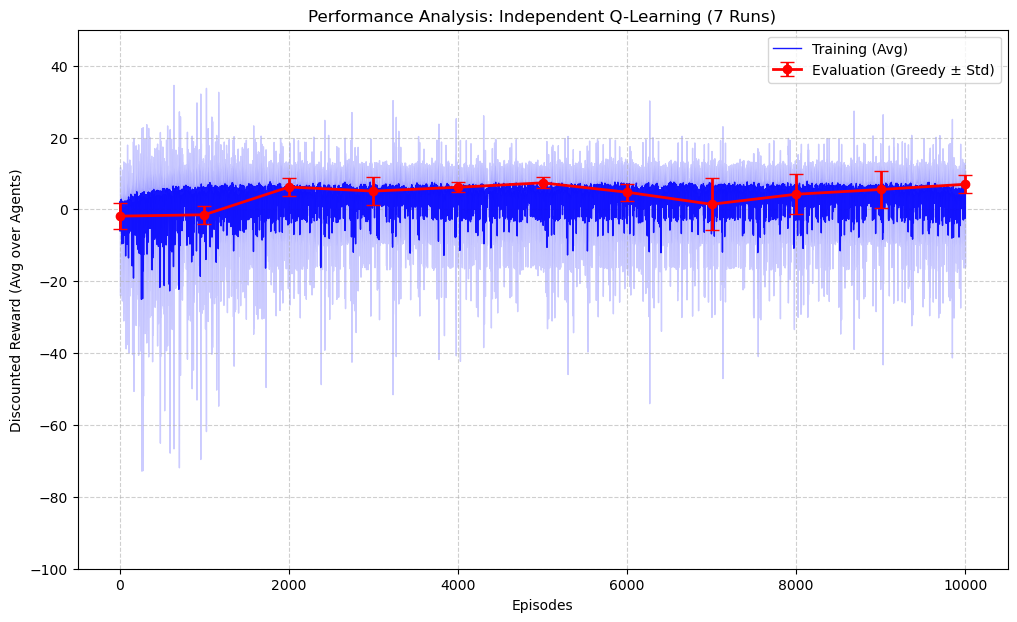

In [14]:
# --- DATA PROCESSING ---
# Convert lists to 2D Numpy Arrays
# Shape: (7 runs, 10000 episodes)
train_data = np.array(all_training_rewards)
# Shape: (7 runs, 11 eval points)
eval_data = np.array(all_eval_rewards)

# Calculate Statistics (Axis 0 = Across the 7 runs)
train_mean = np.mean(train_data, axis=0)
train_std = np.std(train_data, axis=0)

eval_mean = np.mean(eval_data, axis=0)
eval_std = np.std(eval_data, axis=0)

# Define X-Axis for Training
x_train = np.arange(len(train_mean))
#x_eval = np.array(all_eval_x_points)
x_eval = np.linspace(0, len(train_rewards_mean), len(eval_rewards_mean))

# --- PLOTTING ---
plt.figure(figsize=(12, 7))

# 1. Training Data (Blue Line + Shaded Error Region)
plt.plot(x_train, train_mean, color='blue', alpha=0.9, label='Training (Avg)', linewidth=1)
# The "Shaded Error Region"
plt.fill_between(
    x_train, 
    train_mean - train_std, # Lower Bound
    train_mean + train_std, # Upper Bound
    color='blue', 
    alpha=0.2 # Transparency
)

# 2. Evaluation Data (Red Dots + Vertical Error Bars)
plt.errorbar(
    x_eval, 
    eval_mean, 
    yerr=eval_std, 
    fmt='o-',        # Line with Dot markers
    color='red', 
    capsize=5,       # Caps on the error bars
    linewidth=2, 
    label='Evaluation (Greedy ± Std)'
)

# Formatting
plt.xlabel('Episodes')
plt.ylabel('Discounted Reward (Avg over Agents)')
plt.title(f'Performance Analysis: Independent Q-Learning ({NUM_RUNS} Runs)')
plt.ylim(-100, 50) # Zoom to relevant area
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

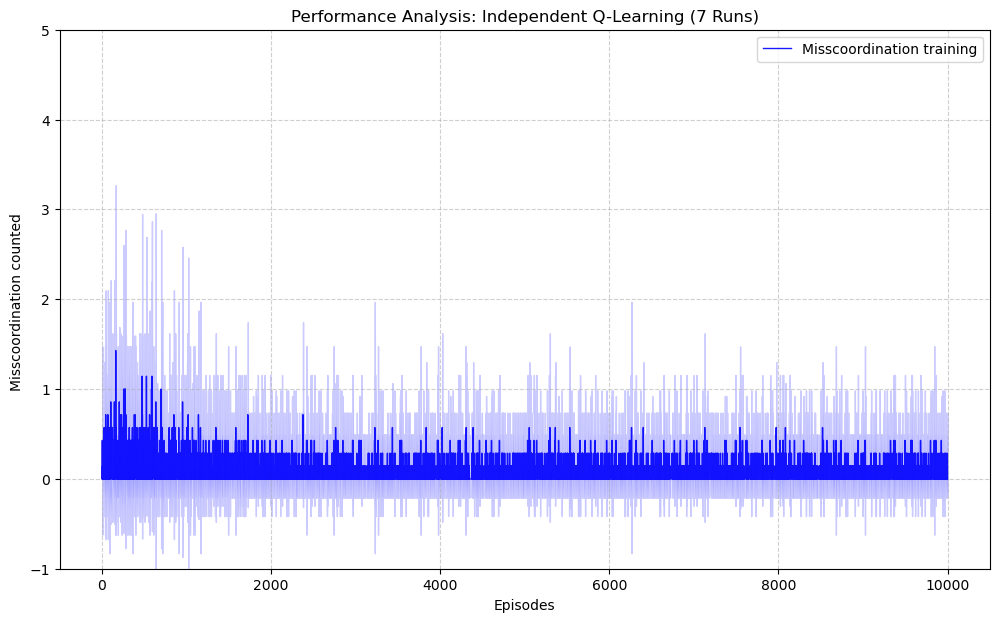

In [15]:
# --- DATA PROCESSING ---
# Convert lists to 2D Numpy Arrays
# Shape: (7 runs, 10000 episodes)
train_data = np.array(all_collisions)
# Shape: (7 runs, 11 eval points)
#eval_data = np.array(all_eval_rewards)

# Calculate Statistics (Axis 0 = Across the 7 runs)
train_mean = np.mean(train_data, axis=0)
train_std = np.std(train_data, axis=0)

#eval_mean = np.mean(eval_data, axis=0)
#eval_std = np.std(eval_data, axis=0)

# Define X-Axis for Training
x_train = np.arange(len(train_mean))
#x_eval = np.linspace(0, len(train_rewards_mean), len(eval_rewards_mean))

# --- PLOTTING ---
plt.figure(figsize=(12, 7))

# 1. Training Data (Blue Line + Shaded Error Region)
plt.plot(x_train, train_mean, color='blue', alpha=0.9, label='Misscoordination training', linewidth=1)
# The "Shaded Error Region"
plt.fill_between(
    x_train, 
    train_mean - train_std, # Lower Bound
    train_mean + train_std, # Upper Bound
    color='blue', 
    alpha=0.2 # Transparency
)

# 2. Evaluation Data (Red Dots + Vertical Error Bars)


# Formatting
plt.xlabel('Episodes')
plt.ylabel('Misscoordination counted ')
plt.title(f'Performance Analysis: Independent Q-Learning ({NUM_RUNS} Runs)')
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True)) # <--- Forza Interi
plt.ylim(-1, 5) # Zoom to relevant area
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

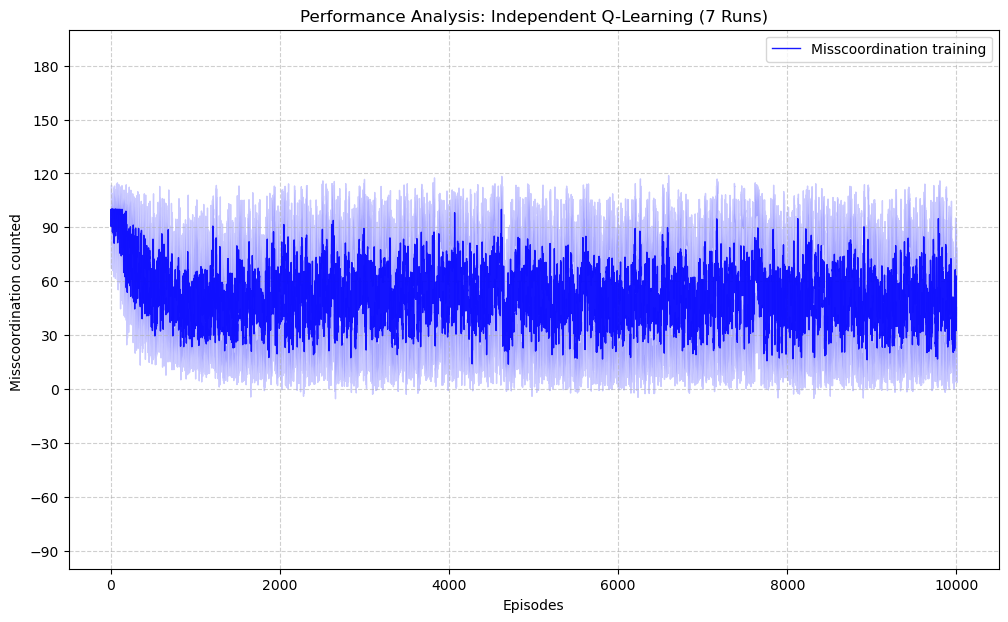

In [ ]:
# --- DATA PROCESSING ---
# Convert lists to 2D Numpy Arrays
# Shape: (7 runs, 10000 episodes)
train_data = np.array(all_steps)
# Shape: (7 runs, 11 eval points)
#eval_data = np.array(all_eval_rewards)

# Calculate Statistics (Axis 0 = Across the 7 runs)
train_mean = np.mean(train_data, axis=0)
train_std = np.std(train_data, axis=0)

#eval_mean = np.mean(eval_data, axis=0)
#eval_std = np.std(eval_data, axis=0)

# Define X-Axis for Training
x_train = np.arange(len(train_mean))
#x_eval = np.linspace(0, len(train_rewards_mean), len(eval_rewards_mean))

# --- PLOTTING ---
plt.figure(figsize=(12, 7))

# 1. Training Data (Blue Line + Shaded Error Region)
plt.plot(x_train, train_mean, color='blue', alpha=0.9, label='Misscoordination training', linewidth=1)
# The "Shaded Error Region"
plt.fill_between(
    x_train, 
    train_mean - train_std, # Lower Bound
    train_mean + train_std, # Upper Bound
    color='blue', 
    alpha=0.2 # Transparency
)

# 2. Evaluation Data (Red Dots + Vertical Error Bars)


# Formatting
plt.xlabel('Episodes')
plt.ylabel('Misscoordination counted ')
plt.title(f'Performance Analysis: Independent Q-Learning ({NUM_RUNS} Runs)')
plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True)) # <--- Forza Interi
plt.ylim(-100, 200) # Zoom to relevant area
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()